# GPU training on Gaia DR3 with CatalogDataset

This notebook trains a small classifier on Gaia DR3 with `CatalogDataset` and
`CatalogDataLoader`, and measures how much the LSDB side of the pipeline holds back the GPU.

It is **pre-executed**: it needs a CUDA GPU, network access to `data.lsdb.io` (or a local copy of
the catalog), and roughly an hour to run. The hardware it ran on is printed below.

The notebook covers:

1. **Data**: about 1.8 billion Gaia DR3 sources. We keep a handful of photometric and astrometric
   columns and label each source as a star, galaxy or quasar.
2. **Model**: an MLP that predicts the class from magnitudes, colors, parallax and proper motion.
   It does no real science. It is a stand-in workload with a tunable GPU cost.
3. **Benchmark**: the two ways of feeding the GPU (mode A and mode B, below), each at several
   CPU worker counts.
4. **Training**: a few epochs with the faster mode, then an evaluation on held-out sky.

## Two ways to feed the GPU

`CatalogDataset` streams partitions with `lsdb.streams.CatalogStream`, and either dask or PyTorch can
supply the parallelism.

**Mode A: a dask client and one torch process.**
`CatalogDataset(..., client=client)` with `CatalogDataLoader(dataset, num_workers=0)`.

- The dask workers read and filter the `partitions_per_chunk` partitions of a chunk in parallel.
- `CatalogStream` keeps **one chunk** in flight. While the training loop works through chunk *i*,
  chunk *i + 1* is computed. Parallelism across dask workers therefore depends on
  `partitions_per_chunk`, and we set it to at least the number of workers.
- The finished chunk is concatenated on a dask worker and sent to the main process.
- The main process shuffles the chunk, cuts it into batches, converts them to tensors, and runs
  the training step. This per-batch Python work shares one interpreter (and its GIL) with the
  training loop.

**Mode B: the synchronous dask scheduler in several torch workers.**
`CatalogDataLoader(dataset, num_workers=k)` with no client.

- Each torch worker process owns a disjoint shard of partitions. It computes them one at a time
  with dask's synchronous scheduler, then shuffles, batches and converts them to tensors.
- PyTorch keeps `prefetch_factor` finished batches per worker waiting in a queue.
- Workers are started from a `forkserver` that has torch and LSDB preloaded. This is much faster
  than `spawn`, and it avoids the problems of forking the main process (see "Why mode B uses a
  preloaded forkserver").
- The main process only receives tensors, copies them to the GPU, and trains.

For a given worker count, both modes use the same number of CPU processes (`k` dask workers or `k`
torch workers, plus the main process).

### Known issues with mode B

Two problems affected `CatalogDataLoader(num_workers > 0)`. The first is worked around in this
notebook; the second is fixed in `CatalogDataset`.

**1. Forked workers cannot read remote catalogs.** A catalog opened over HTTP(S) holds an fsspec
filesystem whose event loop was created in the main process. When torch forks a worker, the worker
inherits that filesystem, and fsspec refuses to use it:

```
RuntimeError: This class is not fork-safe
```

`open_catalog` already reads from the server, so this happens for any remote catalog. Fork is the
default start method on Linux before Python 3.14, so mode B fails with default settings. The
existing tests use in-memory catalogs, so they don't catch it.
*Workaround here:* start workers from a preloaded `forkserver` (see the next section). Each worker
receives a pickled copy of the dataset and so gets a fresh filesystem.

**2. (Fixed) User functions could not be sent to `spawn` or `forkserver` workers.** With either
start method, each worker gets a pickled copy of the dataset. PyTorch uses Python's standard
pickle, which saves functions by name and cannot handle lambdas, closures or functions defined in
a notebook. That affected any such function in the catalog's pipeline (for example from
`map_partitions`) or the `collate_fn`, and also `Catalog.query`, which stores a lambda internally:

```
AttributeError: Can't get local object 'HealpixDataset.query.<locals>.<lambda>'
```

*Fix:* `CatalogDataset` now pickles its catalog and `collate_fn` with `cloudpickle`, as dask does in
mode A, so the notebook filters with `query` again. Objects that cannot be pickled at all (open
files, locks, connections) still fail, and every object a function references is copied to each
worker.

Possible fix for issue 1: make a preloaded `forkserver` the default in `CatalogDataLoader`.

### Why mode B uses a preloaded forkserver

The second run of this notebook started mode B workers with `spawn` (its outputs are in commit
`ee65932`). Startup took 16 s with 1 worker and 357 s with 32. Workers that aren't persistent pay
this again every epoch, and evaluation pays it once more. At 32 workers, each training epoch took
about 5 minutes, of which only about 40 s was actual training.

We measured worker startup in isolation: the time until every worker had produced its first batch.
These numbers come from a laptop with a small local catalog. The pattern matters, not the absolute
times.

| Start method | 1 worker | 8 workers | Pattern |
|---|---|---|---|
| `spawn` | 4.8 s | 32 s | about 4 s per worker, one after another |
| `forkserver` with nothing preloaded | 4.4 s | 32 s | same as `spawn` |
| `forkserver` with torch and LSDB preloaded | 0.7 s | 1.3 s | about 0.06 s per worker, after a one-time server start of about 4 s |
| `fork` | 0.3 s | 0.3 s | nearly instant |

**Why `spawn` is slow.** PyTorch starts the workers one at a time inside `iter(loader)`. Each start
waits until the new Python interpreter has imported torch and LSDB and read its pickled copy of the
dataset, so startup grows linearly with the worker count. On a network filesystem, where imports
are slow, it took about 11 s per worker.

**Why not `fork`.** Forking the main process is fastest, but it isn't safe here. A forked worker
inherits the main process's HTTP filesystem, which fsspec refuses to use (issue 1 above). LSDB also
imports lance, which warns that it is not fork-safe and may deadlock in a forked child.

**Why a preloaded `forkserver`.** A separate server process imports torch and LSDB once, and each
worker is forked from it. That server has never opened a catalog or a file, so it is safe to fork,
and each worker still receives its own pickled dataset, with a fresh filesystem. Starting the server
costs about as much as starting one `spawn` worker, but only once per Python session, not once per
epoch. Lance still prints its fork warning, but the warning itself recommends `forkserver`.
The dataset is pickled with `cloudpickle`, so functions in the catalog work in these workers
(issue 2 above). We have not yet tested
this setup against the remote HTTPS catalog.

## Lessons from the first run

The first run of this notebook was decisively **GPU-bound**: every configuration trained at about the
same speed, whatever the data side did. Its full outputs are in the git history (commit `bc07060`).
The current defaults are changed as a result.

**Setup:** one NVIDIA L40, 128 CPU cores, a local copy of the Gaia DR3 HATS catalog, 256 training
partitions (about 170M rows after filtering), `BATCH_SIZE = 8192`, `HIDDEN = 1024`, `DEPTH = 6`
(25.2M parameters), `BENCH_SECONDS = 90`, and 1 to 32 workers.

| Measurement | Mode A (dask client) | Mode B (torch workers) |
|---|---|---|
| GPU ceiling | 0.23M rows/s (36 ms per step) | same |
| Data ceiling | 1.20M rows/s (1 worker), peaks at 2.02M (8), falls to 1.28M (32) | 0.79M rows/s (1 worker), rises to 2.01M (32) |
| Training throughput | 0.21–0.23M rows/s at every worker count | 0.22–0.24M rows/s at every worker count |
| GPU-busy fraction | 0.87–0.91 | 0.92–0.99 |
| Startup (time to first batch) | 5–36 s | 22 s (1 worker) to 324 s (32 workers) |

**What we learned:**

1. **The model, not LSDB, was the bottleneck.** What decides the bottleneck is how much compute the
   model does per byte of input. Training an MLP costs about 6 FLOPs per parameter per row, so
   the 25M-parameter model needed about 150 MFLOP per row. A row is only 17 columns, about 84
   bytes. That is about 1.8 MFLOP per input byte, roughly 10× more than training ResNet-50 on
   ImageNet images. The GPU could take only about 19 MB/s of input, while LSDB delivered 70–170
   MB/s. Realistic models for a few tabular features are 10–100× cheaper per row, so the defaults
   are now a 0.5M-parameter model with larger batches, which should move the GPU ceiling above the
   data ceiling.
2. **Synchronizing after every step overstated mode A's cost.** Mode A converts each batch on the
   main thread (about 5 ms per step), and with a synchronization after every step, that work could
   not overlap the 33 ms GPU step. A normal training loop would hide most of it. The benchmark now
   times the GPU with CUDA events and never waits for it.
3. **Some configurations ran out of data.** At 2M rows/s, the 256 training partitions last only
   about 85 s, less than the 90 s window. The benchmark now uses its own set of
   `N_BENCH_PARTITIONS` partitions.
4. **Mode B startup grows by about 10 s per worker,** and non-persistent workers pay it again every
   epoch. Since confirmed: with `spawn`, PyTorch starts the workers one after another, and each one
   re-imports torch and LSDB. The notebook now uses a preloaded `forkserver`; see "Why mode B uses
   a preloaded forkserver".
5. **Mode A stops scaling after about 8 workers.** With `partitions_per_chunk = 32`, each chunk is
   about 20M rows. It is concatenated on one dask worker, sent to the main process, and shuffled
   there on a single thread.
6. **The GPU ceiling measured slightly low.** Mode B training reached 1.05–1.08× the ceiling, so
   the 50-step measurement was 5–8% pessimistic. It now runs 200 steps.

In [1]:
import multiprocessing
import os
import threading
import time
from contextlib import contextmanager, nullcontext

import lsdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from dask.distributed import Client, LocalCluster
from torch import nn

import lsdb_ml
from lsdb_ml import CatalogDataLoader, CatalogDataset

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"lsdb {lsdb.__version__}, lsdb-ml {lsdb_ml.__version__}, torch {torch.__version__}")
N_CPUS = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
print(f"CPU cores available: {N_CPUS}")
print(f"Device: {device}", f"({torch.cuda.get_device_name()})" if device.type == "cuda" else "")

lsdb 0.11.2, lsdb-ml 0.1.dev35+ge6177149f, torch 2.14.0+cu130
CPU cores available: 128
Device: cuda (NVIDIA L40)


## Configuration

All the settings are in this cell.

- **Data:** `CATALOG_URL` is read over HTTP by default, so network bandwidth is part of what the
  benchmark measures. To measure only LSDB's CPU cost, point it at a local copy on fast disk.
- **Model size:** `HIDDEN` and `DEPTH` set how much work the GPU does per row. A larger model makes
  the GPU slower, so it is easier for the data pipeline to keep up. A small model spends much of
  each step on fixed per-step costs, so a larger `BATCH_SIZE` raises its GPU ceiling.
- **Benchmark cost:** each benchmark configuration runs for `BENCH_SECONDS` once its first batch
  arrives. The two sweeps (data only, then training) together take about
  `2 × len(CONFIGS) × (BENCH_SECONDS + startup)`.

In [2]:
# CATALOG_URL = "https://data.lsdb.io/hats/gaia_dr3"
CATALOG_URL = "/astro/store/shire/hats/catalogs/gaia_dr3"
SEED = 42

# Data split, in partitions. Gaia DR3 has 2016 partitions with about 0.6M usable rows each.
N_TRAIN_PARTITIONS = 256
N_VAL_PARTITIONS = 32
N_BENCH_PARTITIONS = 1024  # benchmark set; large enough that no configuration runs out of data
N_STATS_PARTITIONS = 16  # used to compute feature normalization and class weights

# Model and optimization. The first run used BATCH_SIZE = 8192, HIDDEN = 1024, DEPTH = 6 (25M
# parameters), which made the GPU the bottleneck everywhere; see "Lessons from the first run".
BATCH_SIZE = 32768
HIDDEN = 256
DEPTH = 2
LEARNING_RATE = 1e-3
USE_AMP = device.type == "cuda"  # bfloat16 autocast
EPOCHS = 2

# Data loading
PIN_MEMORY = device.type == "cuda"
PREFETCH_FACTOR = 4  # mode B: batches queued per torch worker

# Benchmark
BENCH_SECONDS = 90  # steady-state measurement window per configuration
WORKER_COUNTS = [n for n in (1, 2, 4, 8, 16, 32) if n < N_CPUS]

# Each configuration is one data pipeline. In mode A, partitions_per_chunk is how many partitions
# the dask workers compute in parallel. Add entries to try other settings, e.g.
# dict(mode="A", workers=8, partitions_per_chunk=16) to give the dask workers more work per chunk.
CONFIGS = []
for n in WORKER_COUNTS:
    CONFIGS.append(dict(mode="A", workers=n, partitions_per_chunk=n))
    CONFIGS.append(dict(mode="B", workers=n, partitions_per_chunk=1))
pd.DataFrame(CONFIGS)

,mode,workers,partitions_per_chunk
0,A,1,1
1,B,1,1
2,A,2,2
3,B,2,1
4,A,4,4
5,B,4,1
6,A,8,8
7,B,8,1
8,A,16,16
9,B,16,1


## Data: Gaia DR3

**Features.** G, BP and RP magnitudes and colors, parallax, proper motion, astrometric quality
(RUWE, excess noise), the BP/RP flux excess, and Galactic latitude.

**Labels.** Gaia's Discrete Source Classifier (DSC) gives each source a probability of being a
star, galaxy or quasar (`classprob_dsc_combmod_*`). The label is the most probable class. DSC uses
the BP/RP spectra, which our model does not see, so this is a distillation task: can the summary
photometry and astrometry reproduce the spectra-based classification? Non-stellar sources make up
well under 1% of the data, so the classes are very imbalanced.

`CatalogDataset`'s default collate does not support missing values. We keep only rows where every
column is present. LSDB applies the filter lazily inside each partition's computation, so it is
part of the data-side cost we measure.

In [3]:
FEATURES = [
    "phot_g_mean_mag",
    "phot_bp_mean_mag",
    "phot_rp_mean_mag",
    "bp_rp",
    "bp_g",
    "g_rp",
    "parallax",
    "parallax_over_error",
    "pmra",
    "pmdec",
    "ruwe",
    "astrometric_excess_noise",
    "phot_bp_rp_excess_factor",
    "b",
]
CLASSES = ["star", "galaxy", "quasar"]
PROB_COLUMNS = [f"classprob_dsc_combmod_{name}" for name in CLASSES]
COLUMNS = FEATURES + PROB_COLUMNS

gaia = lsdb.open_catalog(CATALOG_URL, columns=COLUMNS)
# Keep rows with no missing values, then select only the columns the model uses (open_catalog
# also loads ra/dec).
gaia = gaia.query(" and ".join(f"{col}.notna()" for col in COLUMNS))[COLUMNS]
gaia

,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,bp_g,g_rp,parallax,parallax_over_error,pmra,pmdec,ruwe,astrometric_excess_noise,phot_bp_rp_excess_factor,b,classprob_dsc_combmod_star,classprob_dsc_combmod_galaxy,classprob_dsc_combmod_quasar
npartitions=2016,,,,,,,,,,,,,,,,,
"Order: 2, Pixel: 0",float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],double[pyarrow],float[pyarrow],double[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 3, Pixel: 766",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 3, Pixel: 767",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


We split by **partition**, so the validation set is a separate region of the sky from the training
set. That is a stricter test than a random row split, because neighboring sources are correlated.

The benchmark uses its own, larger set of partitions (which includes the training set but never the
validation set), so that even the fastest configuration does not run out of data during its window.

In [4]:
order = np.random.default_rng(SEED).permutation(gaia.npartitions)
val_idx = order[:N_VAL_PARTITIONS]
rest = order[N_VAL_PARTITIONS:]  # never used for validation
train_idx = rest[:N_TRAIN_PARTITIONS]
bench_idx = rest[:N_BENCH_PARTITIONS]
stats_idx = train_idx[:N_STATS_PARTITIONS]

train_catalog = gaia.partitions[train_idx.tolist()]
val_catalog = gaia.partitions[val_idx.tolist()]
bench_catalog = gaia.partitions[bench_idx.tolist()]
print(
    f"train: {train_catalog.npartitions} partitions, val: {val_catalog.npartitions} partitions, "
    f"benchmark: {bench_catalog.npartitions} partitions"
)

train: 256 partitions, val: 32 partitions, benchmark: 1024 partitions


A sample of training partitions gives the feature normalization and the class frequencies.

In [5]:
%%time
stats_frame = gaia.partitions[stats_idx.tolist()].compute()
class_counts = np.bincount(stats_frame[PROB_COLUMNS].to_numpy().argmax(axis=1), minlength=len(CLASSES))
print(f"{len(stats_frame):,} rows in {N_STATS_PARTITIONS} partitions")
pd.Series(class_counts, index=CLASSES, name="sources")

Building task graph...


Computing Catalog:   0%|          | 0/48 [00:00<?, ?it/s]

10,750,813 rows in 16 partitions
CPU times: user 5.93 s, sys: 1.77 s, total: 7.69 s
Wall time: 1.31 s


star      10557574
galaxy       10254
quasar      182985
Name: sources, dtype: int64

## Model

Batches from `CatalogDataset` are dictionaries of 1-D tensors, one per column (see
`collate_catalog`). We move the dictionary to the GPU as is and do everything else there:

- `Featurize` turns the raw columns into well-scaled inputs. For example, it takes `asinh` of
  heavy-tailed quantities like parallax and `sin|b|` of the latitude, then standardizes with
  statistics from the sample above.
- `labels` takes the argmax of the DSC probabilities.
- `GaiaClassifier` is a residual MLP with about 0.5M parameters at the defaults, a realistic size
  for 14 tabular inputs. The first run used a 25M-parameter version, about 50× more compute per
  row, and the GPU was the bottleneck in every configuration (see "Lessons from the first run").

The loss weights each class by the inverse square root of its frequency. That boosts the rare
galaxies and quasars without letting them dominate.

In [6]:
class Featurize(nn.Module):
    """Turns a batch of raw Gaia columns into standardized model inputs."""

    n_features = 13

    def __init__(self):
        super().__init__()
        self.register_buffer("mean", torch.zeros(self.n_features))
        self.register_buffer("std", torch.ones(self.n_features))

    def transform(self, batch):
        """Raw columns to unnormalized features of shape [B, n_features]."""
        c = {name: batch[name].float() for name in FEATURES}
        pm = torch.hypot(c["pmra"], c["pmdec"])
        return torch.stack(
            [
                c["phot_g_mean_mag"],
                c["phot_bp_mean_mag"],
                c["phot_rp_mean_mag"],
                c["bp_rp"],
                c["bp_g"],
                c["g_rp"],
                torch.asinh(c["parallax"]),
                torch.asinh(c["parallax_over_error"]),
                torch.log1p(pm),
                torch.log(c["ruwe"]),
                torch.log1p(c["astrometric_excess_noise"]),
                torch.log(c["phot_bp_rp_excess_factor"]),
                torch.sin(torch.deg2rad(c["b"])).abs(),
            ],
            dim=1,
        )

    def fit(self, batch):
        """Set the normalization from a sample batch."""
        features = self.transform(batch)
        self.mean.copy_(features.mean(dim=0))
        self.std.copy_(features.std(dim=0))
        return self

    def forward(self, batch):
        """Standardized features of shape [B, n_features]."""
        return (self.transform(batch) - self.mean) / self.std


class Block(nn.Module):
    """Pre-norm residual MLP block."""

    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(width), nn.Linear(width, 2 * width), nn.GELU(), nn.Linear(2 * width, width)
        )

    def forward(self, x):
        """Apply the block with a skip connection."""
        return x + self.net(x)


class GaiaClassifier(nn.Module):
    """Residual MLP from Gaia columns to class logits."""

    def __init__(self, featurize, hidden, depth, n_classes):
        super().__init__()
        self.featurize = featurize
        self.embed = nn.Linear(featurize.n_features, hidden)
        self.blocks = nn.Sequential(*[Block(hidden) for _ in range(depth)])
        self.head = nn.Sequential(nn.LayerNorm(hidden), nn.Linear(hidden, n_classes))

    def forward(self, batch):
        """Class logits of shape [B, n_classes]."""
        return self.head(self.blocks(self.embed(self.featurize(batch))))


def labels(batch):
    """Index of the most probable DSC class."""
    return torch.stack([batch[col] for col in PROB_COLUMNS], dim=1).argmax(dim=1)


def to_device(batch):
    """Copy a batch dictionary to the training device."""
    if device.type == "mps":  # MPS has no float64
        batch = {name: t.float() if t.dtype == torch.float64 else t for name, t in batch.items()}
    return {name: tensor.to(device, non_blocking=True) for name, tensor in batch.items()}


def sync():
    """Wait for queued GPU work, so wall-clock timings include it."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


# Normalization from up to 1M sampled rows, converted with the same collate as the loader uses.
sample_batch = lsdb_ml.collate_catalog(
    stats_frame.sample(min(len(stats_frame), 1_000_000), random_state=SEED)
)

frequency = (class_counts + 1) / (class_counts + 1).sum()
class_weights = torch.tensor(frequency**-0.5, dtype=torch.float32)
class_weights = (class_weights / class_weights.mean()).to(device)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)


def new_model():
    """A freshly initialized model and its optimizer."""
    torch.manual_seed(SEED)
    model = GaiaClassifier(Featurize().fit(sample_batch), HIDDEN, DEPTH, len(CLASSES)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    return model, optimizer


def train_step(model, optimizer, batch):
    """One optimization step on a batch; returns the loss."""
    batch = to_device(batch)
    with torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_AMP):
        loss = loss_fn(model(batch), labels(batch))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    return loss


if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
model, optimizer = new_model()
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")
print(f"class weights: {dict(zip(CLASSES, class_weights.tolist(), strict=True))}")

0.5M parameters
class weights: {'star': 0.07374323904514313, 'galaxy': 2.3661184310913086, 'quasar': 0.560138463973999}


## Measuring the bottleneck

Three numbers tell us where time goes:

1. **GPU ceiling.** Training steps on one batch that is already on the GPU. No data loading at
   all, so this is the most rows per second the GPU can take for this model and batch size.
2. **Data ceiling.** Iterating the loader without training. This is the most rows per second the
   LSDB pipeline can deliver.
3. **Training.** The real loop. For every step we record how long the loop **waited** on the
   loader and how long the **GPU** spent on the step, including the host-to-device copy. The
   **GPU-busy fraction** is GPU time divided by wall time. Well below 1 means the GPU sat idle
   waiting on data.

If the data side were perfectly overlapped with the GPU, training throughput would be
`min(data ceiling, GPU ceiling)`. When training is slower than both, the two sides compete for
resources. In mode A that is the main process's GIL.

Like a normal training loop, the benchmark never waits for the GPU. The CPU queues each step and
goes straight on to fetch the next batch while the GPU works, so data loading overlaps GPU compute.
GPU time is measured with CUDA events, which the GPU timestamps as it reaches them. (The first run
synchronized after every step instead, which kept mode A's per-batch work from overlapping the GPU;
see "Lessons from the first run".) If the CPU cannot queue a step's kernels as fast as the GPU runs
them, the gaps inside that step count as busy, so treat the busy fraction as an upper bound. If
`nvidia-ml-py` is installed, we also sample the driver's own GPU utilization as an independent
check.

In [7]:
class GpuUtilization:
    """Samples torch.cuda.utilization() (needs nvidia-ml-py) in a background thread."""

    def __init__(self, interval=0.25):
        self.interval, self.samples = interval, []
        self._stop = threading.Event()
        try:
            torch.cuda.utilization()
            self.available = True
        except Exception:
            self.available = False

    def _run(self):
        while not self._stop.wait(self.interval):
            self.samples.append(torch.cuda.utilization())

    def __enter__(self):
        if self.available:
            self._thread = threading.Thread(target=self._run, daemon=True)
            self._thread.start()
        return self

    def __exit__(self, *exc):
        self._stop.set()
        if self.available:
            self._thread.join()

    @property
    def mean(self):
        """Mean utilization in percent, or NaN without samples."""
        return float(np.mean(self.samples)) if self.samples else np.nan


def gpu_ceiling(model, optimizer, steps=200, warmup=20):
    """Rows per second for training on one batch that is already on the device."""
    batch = to_device(lsdb_ml.collate_catalog(stats_frame.iloc[:BATCH_SIZE]))
    for _ in range(warmup):
        train_step(model, optimizer, batch)
    sync()
    start = time.perf_counter()
    for _ in range(steps):
        train_step(model, optimizer, batch)
    sync()
    elapsed = time.perf_counter() - start
    return dict(rows_per_s=steps * BATCH_SIZE / elapsed, ms_per_step=1e3 * elapsed / steps)


def run(loader, model=None, optimizer=None, seconds=BENCH_SECONDS):
    """Iterate a loader for `seconds` after its first batch, training if a model is given.

    The first batch is excluded from the steady-state numbers and reported as startup time. On CUDA,
    each step's GPU time is measured with CUDA events, so the loop never waits for the GPU and data
    loading overlaps GPU work, as in a normal training loop. Other devices synchronize after every
    step instead.
    """
    use_events = model is not None and device.type == "cuda"
    start = time.perf_counter()
    iterator = iter(loader)  # starts torch workers in mode B, so start no threads before this
    batch = next(iterator)
    startup = time.perf_counter() - start

    wait = gpu = 0.0
    rows = steps = 0
    events = []
    with GpuUtilization() if use_events else nullcontext() as util:
        window_start = time.perf_counter()
        while True:
            if use_events:
                begin, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                begin.record()
                train_step(model, optimizer, batch)
                end.record()
                events.append((begin, end))
            elif model is not None:
                t0 = time.perf_counter()
                train_step(model, optimizer, batch)
                sync()
                gpu += time.perf_counter() - t0
            rows += len(batch[COLUMNS[0]])
            steps += 1
            t1 = time.perf_counter()
            if t1 - window_start >= seconds:
                break
            try:
                batch = next(iterator)
            except StopIteration:
                print("  (data exhausted before the time window ended)")
                break
            wait += time.perf_counter() - t1
        sync()  # include GPU work still queued when the window ends
        elapsed = time.perf_counter() - window_start
    del iterator  # shuts down torch workers
    if use_events:
        gpu = sum(begin.elapsed_time(end) for begin, end in events) / 1e3
    return dict(
        startup_s=startup,
        rows_per_s=rows / elapsed,
        gpu_busy=gpu / elapsed if model is not None else np.nan,
        wait_ms_per_step=1e3 * wait / steps,
        gpu_ms_per_step=1e3 * gpu / steps if model is not None else np.nan,
        gpu_util_pct=util.mean if use_events else np.nan,
        steps=steps,
    )


# Mode B starts its workers from a fork server that has already imported these modules, so a
# worker starts in a fraction of a second instead of re-importing everything (see "Why mode B uses
# a preloaded forkserver"). The server itself starts once, on first use.
MP_CONTEXT = multiprocessing.get_context("forkserver")
MP_CONTEXT.set_forkserver_preload(["torch", "lsdb", "lsdb_ml", "nested_pandas"])


@contextmanager
def pipeline(mode, workers, partitions_per_chunk, catalog=train_catalog, shuffle=True):
    """A CatalogDataLoader in mode A (dask client) or mode B (torch workers)."""
    dataset_kwargs = dict(
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
        partitions_per_chunk=partitions_per_chunk,
        drop_last=shuffle,
    )
    if mode == "A":
        cluster = LocalCluster(
            n_workers=workers, threads_per_worker=1, processes=True, dashboard_address=":0"
        )
        client = Client(cluster)
        try:
            dataset = CatalogDataset(catalog, client=client, **dataset_kwargs)
            yield CatalogDataLoader(dataset, pin_memory=PIN_MEMORY)
        finally:
            client.close()
            cluster.close()
    else:
        dataset = CatalogDataset(catalog, **dataset_kwargs)
        # Not plain fork: a forked worker inherits the parent's HTTP filesystem, which fsspec
        # refuses to use after a fork ("This class is not fork-safe").
        yield CatalogDataLoader(
            dataset,
            num_workers=workers,
            prefetch_factor=PREFETCH_FACTOR,
            pin_memory=PIN_MEMORY,
            multiprocessing_context=MP_CONTEXT,
        )

### GPU ceiling

In [8]:
ceiling = gpu_ceiling(*new_model())
print(f"GPU ceiling: {ceiling['rows_per_s'] / 1e6:.2f}M rows/s ({ceiling['ms_per_step']:.1f} ms per step)")

GPU ceiling: 4.86M rows/s (6.7 ms per step)


### Data ceiling

Each configuration iterates the training loader for `BENCH_SECONDS` without touching the GPU.

In [9]:
data_results = []
for config in CONFIGS:
    print(f"data only: {config}")
    with pipeline(**config, catalog=bench_catalog) as loader:
        data_results.append({**config, **run(loader)})
data_df = pd.DataFrame(data_results)
data_df[["mode", "workers", "partitions_per_chunk", "startup_s", "rows_per_s", "wait_ms_per_step"]]

data only: {'mode': 'A', 'workers': 1, 'partitions_per_chunk': 1}


2026-11-13 14:18:13,638 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute(('read_pixel-984aefe81114925ee78f2752b54323b3', 129))" coro=<Worker.execute() done, defined at /astro/users/brantd/.conda/envs/aion_training/lib/python3.13/site-packages/distributed/worker_state_machine.py:3606>> ended with CancelledError


data only: {'mode': 'B', 'workers': 1, 'partitions_per_chunk': 1}


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/site-packages/lance/__init__.py:358: UserWarning: lance is not fork-safe. If you are using multiprocessing, use spawn or forkserver instead.
  warnings.warn(
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()


data only: {'mode': 'A', 'workers': 2, 'partitions_per_chunk': 2}
data only: {'mode': 'B', 'workers': 2, 'partitions_per_chunk': 1}


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()


... (6 outputs left out)

  (data exhausted before the time window ended)
data only: {'mode': 'A', 'workers': 32, 'partitions_per_chunk': 32}
data only: {'mode': 'B', 'workers': 32, 'partitions_per_chunk': 1}


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been rese

  (data exhausted before the time window ended)


,mode,workers,partitions_per_chunk,startup_s,rows_per_s,wait_ms_per_step
0,A,1,1,3.642579,2.967626e+06,11.039667
1,B,1,1,12.103820,2.492075e+06,13.146647
2,A,2,2,4.039435,4.182055e+06,7.833478
3,B,2,1,1.303482,3.222351e+06,10.167022
4,A,4,4,4.352905,5.433655e+06,6.028813
5,B,4,1,1.259003,4.244524e+06,7.717749
6,A,8,8,4.112280,5.304877e+06,6.175287
7,B,8,1,1.425721,6.057135e+06,5.407551
8,A,16,16,10.135783,4.805836e+06,6.816694
9,B,16,1,1.772164,9.577015e+06,3.416968


### Training throughput

Now the same pipelines feed real training steps. Every configuration uses a fresh model, so the
measurements do not depend on the order they run in. Remote reads can still get faster as the
server's caches warm up. Since mode A and mode B alternate at every worker count, any such drift
affects both modes about equally.

In [10]:
train_results = []
for config in CONFIGS:
    print(f"training: {config}")
    model, optimizer = new_model()
    with pipeline(**config, catalog=bench_catalog) as loader:
        train_results.append({**config, **run(loader, model, optimizer)})
train_df = pd.DataFrame(train_results)
train_df["data_ceiling_rows_per_s"] = data_df["rows_per_s"]
train_df["of_gpu_ceiling"] = train_df["rows_per_s"] / ceiling["rows_per_s"]
train_df[
    [
        "mode",
        "workers",
        "partitions_per_chunk",
        "startup_s",
        "rows_per_s",
        "data_ceiling_rows_per_s",
        "of_gpu_ceiling",
        "gpu_busy",
        "gpu_util_pct",
        "wait_ms_per_step",
        "gpu_ms_per_step",
    ]
]

training: {'mode': 'A', 'workers': 1, 'partitions_per_chunk': 1}
training: {'mode': 'B', 'workers': 1, 'partitions_per_chunk': 1}


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()


training: {'mode': 'A', 'workers': 2, 'partitions_per_chunk': 2}
training: {'mode': 'B', 'workers': 2, 'partitions_per_chunk': 1}


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()


training: {'mode': 'A', 'workers': 4, 'partitions_per_chunk': 4}
training: {'mode': 'B', 'workers': 4, 'partitions_per_chunk': 1}


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been rese

... (3 outputs left out)

/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been rese

training: {'mode': 'A', 'workers': 32, 'partitions_per_chunk': 32}
training: {'mode': 'B', 'workers': 32, 'partitions_per_chunk': 1}


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been rese

,mode,workers,partitions_per_chunk,startup_s,rows_per_s,data_ceiling_rows_per_s,of_gpu_ceiling,gpu_busy,gpu_util_pct,wait_ms_per_step,gpu_ms_per_step
0,A,1,1,4.660653,2.425195e+06,2.967626e+06,0.499459,0.564208,NaN,9.878297,7.623288
1,B,1,1,1.218168,2.224849e+06,2.492075e+06,0.458198,0.514580,NaN,10.977394,7.578840
2,A,2,2,9.055392,2.786059e+06,4.182055e+06,0.573777,0.636872,NaN,6.893288,7.490523
3,B,2,1,1.359021,2.662728e+06,3.222351e+06,0.548378,0.615621,NaN,7.345774,7.575943
4,A,4,4,8.187761,2.744601e+06,5.433655e+06,0.565239,0.628745,NaN,6.400189,7.506632
5,B,4,1,1.362496,3.334976e+06,4.244524e+06,0.686825,0.790388,NaN,4.098353,7.766003
6,A,8,8,4.284305,2.647471e+06,5.304877e+06,0.545236,0.609656,NaN,6.431610,7.545772
7,B,8,1,1.394436,4.015627e+06,6.057135e+06,0.827002,0.953784,NaN,1.032200,7.782995
8,A,16,16,10.464075,2.484369e+06,4.805836e+06,0.511646,0.578620,NaN,6.980990,7.631810
9,B,16,1,1.670490,4.273789e+06,9.577015e+06,0.880169,0.995040,NaN,0.199023,7.629175


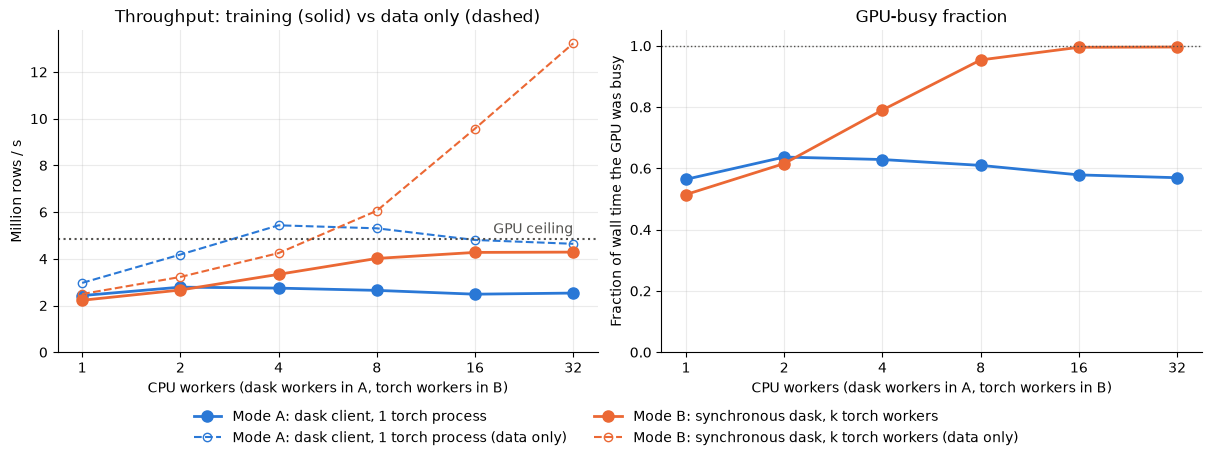

In [11]:
MODE_STYLE = {
    "A": dict(color="#2a78d6", label="Mode A: dask client, 1 torch process"),
    "B": dict(color="#eb6834", label="Mode B: synchronous dask, k torch workers"),
}
INK, MUTED = "#0b0b0b", "#52514e"

fig, (ax_rate, ax_busy) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for mode, style in MODE_STYLE.items():
    train = train_df[train_df["mode"] == mode]
    data = data_df[data_df["mode"] == mode]
    ax_rate.plot(train["workers"], train["rows_per_s"] / 1e6, "o-", lw=2, ms=8, **style)
    ax_rate.plot(
        data["workers"],
        data["rows_per_s"] / 1e6,
        "o--",
        lw=1.5,
        ms=6,
        mfc="none",
        color=style["color"],
        label=f"{style['label']} (data only)",
    )
    ax_busy.plot(train["workers"], train["gpu_busy"], "o-", lw=2, ms=8, **style)

ax_rate.axhline(ceiling["rows_per_s"] / 1e6, color=MUTED, lw=1.5, ls=":")
ax_rate.annotate(
    "GPU ceiling",
    (WORKER_COUNTS[-1], ceiling["rows_per_s"] / 1e6),
    xytext=(0, 4),
    textcoords="offset points",
    ha="right",
    color=MUTED,
)
ax_rate.set(ylabel="Million rows / s", title="Throughput: training (solid) vs data only (dashed)")
ax_rate.set_ylim(bottom=0)
fig.legend(*ax_rate.get_legend_handles_labels(), loc="outside lower center", ncols=2, frameon=False)

ax_busy.axhline(1, color=MUTED, lw=1, ls=":")
ax_busy.set(ylabel="Fraction of wall time the GPU was busy", title="GPU-busy fraction", ylim=(0, 1.05))

for ax in (ax_rate, ax_busy):
    ax.set_xscale("log", base=2)
    ax.set_xticks(WORKER_COUNTS, [str(n) for n in WORKER_COUNTS])
    ax.set_xlabel("CPU workers (dask workers in A, torch workers in B)")
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Reading the results

- **Where do the dashed lines (data ceiling) cross the GPU ceiling?** That is the number of CPU
  workers this model needs before it stops waiting on data. If they never cross, the pipeline is
  data-bound at every worker count we tried. In that case the useful levers are more CPUs, faster
  storage, or less work per row on the data side.
- **The gap between a dashed line and its solid line** is what the training loop costs the data
  side. Mode A's batching and tensor conversion run on the main thread, so expect a larger gap
  there. Mode B moves that work into the workers.
- **`wait_ms_per_step` vs `gpu_ms_per_step`** compares how long the loop blocked on the loader
  with how long the GPU spent on each step. Because the GPU keeps working while the loop waits,
  waiting only costs throughput when it is longer than the GPU time.
- **`startup_s`** is the time to the first batch. In mode A it includes starting the cluster and
  computing a whole chunk of `partitions_per_chunk` partitions. In mode B it includes starting the
  workers and computing one partition per worker.

The shuffling also differs between the modes. In mode A each chunk mixes `partitions_per_chunk`
regions of sky. In mode B each batch comes from a single partition per worker, so batches from one
worker cover only one patch of sky. Very homogeneous batches can hurt training, but this
benchmark does not measure that.

## Train the model

We train for `EPOCHS` epochs with the configuration that had the highest training throughput above,
and evaluate on the held-out validation partitions after every epoch.

In [12]:
best = train_df.loc[train_df["rows_per_s"].idxmax(), ["mode", "workers", "partitions_per_chunk"]].to_dict()
best["workers"], best["partitions_per_chunk"] = int(best["workers"]), int(best["partitions_per_chunk"])
print(f"training with {best}")


@torch.no_grad()
def evaluate(model):
    """Confusion matrix (rows: true class, columns: predicted) on the validation partitions."""
    model.eval()
    confusion = torch.zeros(len(CLASSES), len(CLASSES), dtype=torch.int64, device=device)
    with pipeline(**best, catalog=val_catalog, shuffle=False) as loader:
        for batch in loader:
            batch = to_device(batch)
            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=USE_AMP):
                predicted = model(batch).argmax(dim=1)
            confusion += torch.bincount(
                labels(batch) * len(CLASSES) + predicted, minlength=len(CLASSES) ** 2
            ).view(len(CLASSES), len(CLASSES))
    model.train()
    return confusion.cpu().numpy()


def recall(confusion):
    """Per-class recall from a confusion matrix."""
    return dict(zip(CLASSES, np.diag(confusion) / confusion.sum(axis=1).clip(min=1), strict=True))


model, optimizer = new_model()
history = []
for epoch in range(EPOCHS):
    start = time.perf_counter()
    losses, rows = [], 0
    # A pipeline per epoch, so a mode A cluster is not left running during evaluation. A loader that
    # is reused advances the epoch by itself; with a new loader each time, we set it explicitly.
    with pipeline(**best) as loader:
        loader.dataset.set_epoch(epoch)
        for batch in loader:
            losses.append(train_step(model, optimizer, batch).detach())
            rows += len(batch[COLUMNS[0]])
    losses = torch.stack(losses).float().cpu().numpy()
    elapsed = time.perf_counter() - start
    confusion = evaluate(model)
    history.append(dict(epoch=epoch, losses=losses, confusion=confusion))
    recalls = ", ".join(f"{k} {v:.3f}" for k, v in recall(confusion).items())
    print(
        f"epoch {epoch}: {rows:,} rows in {elapsed / 60:.1f} min ({rows / elapsed / 1e6:.2f}M rows/s), "
        f"mean loss {losses.mean():.4f}, val recall: {recalls}"
    )

training with {'mode': 'B', 'workers': 32, 'partitions_per_chunk': 1}


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been rese

epoch 0: 167,411,712 rows in 0.6 min (4.36M rows/s), mean loss 0.0395, val recall: star 0.996, galaxy 0.925, quasar 0.765


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been reset in the forked child, but a small chance of deadlock remains if other state was mid-operation at fork time. The 'forkserver' or 'spawn' multiprocessing start method is likely a safer alternative.
  pid = os.fork()
/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/multiprocessing/forkserver.py:287: RuntimeWarning: lancedb fork support is experimental: the internal async runtime has been rese

epoch 1: 167,346,176 rows in 0.7 min (3.86M rows/s), mean loss 0.0316, val recall: star 0.996, galaxy 0.903, quasar 0.797


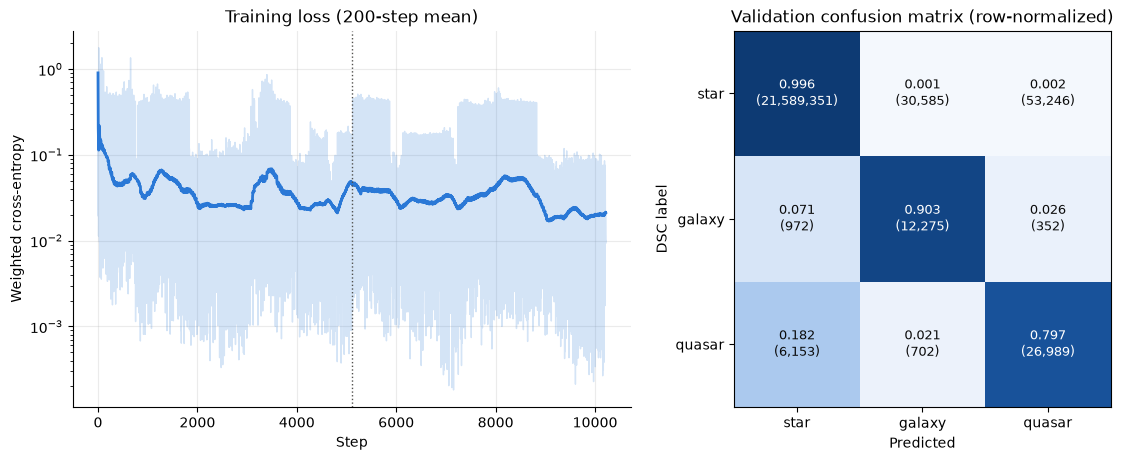

In [13]:
from matplotlib.colors import LinearSegmentedColormap

losses = np.concatenate([h["losses"] for h in history])
confusion = history[-1]["confusion"]
# Row-normalized: each true class sums to 1, so the rare classes are readable.
fraction = confusion / confusion.sum(axis=1, keepdims=True).clip(min=1)

fig, (ax_loss, ax_cm) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
smooth = pd.Series(losses).rolling(200, min_periods=1).mean()
ax_loss.plot(losses, color="#2a78d6", alpha=0.2, lw=1)
ax_loss.plot(smooth, color="#2a78d6", lw=2)
steps_per_epoch = len(history[0]["losses"])
for epoch in range(1, len(history)):
    ax_loss.axvline(epoch * steps_per_epoch, color=MUTED, lw=1, ls=":")
ax_loss.set(
    xlabel="Step", ylabel="Weighted cross-entropy", title="Training loss (200-step mean)", yscale="log"
)
ax_loss.grid(alpha=0.25)
ax_loss.spines[["top", "right"]].set_visible(False)

blues = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#2a78d6", "#0d3a73"])
ax_cm.imshow(fraction, cmap=blues, vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax_cm.text(
            j,
            i,
            f"{fraction[i, j]:.3f}\n({confusion[i, j]:,})",
            ha="center",
            va="center",
            color="white" if fraction[i, j] > 0.5 else INK,
            fontsize=9,
        )
ax_cm.set(
    xticks=range(len(CLASSES)),
    yticks=range(len(CLASSES)),
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    xlabel="Predicted",
    ylabel="DSC label",
    title="Validation confusion matrix (row-normalized)",
)
plt.show()

## Notes and next steps

- **Isolating LSDB's CPU cost.** Reading over HTTP mixes network bandwidth into the data ceiling.
  Rerun with `CATALOG_URL` pointing at a local copy (for example, the training partitions written
  with `train_catalog.write_catalog(...)`) to see the parse, filter and collate cost alone. (Done above)
- **Moving the GPU ceiling.** `HIDDEN`, `DEPTH` and `BATCH_SIZE` set the GPU cost per row. A
  benchmark is only informative near the crossover, where neither side completely dominates.
- **Mode A tuning.** `CatalogStream` keeps one chunk in flight, so dask workers sit idle while the
  slowest partition of a chunk finishes. A larger `partitions_per_chunk` (e.g. twice the worker
  count) balances the load better, but needs more memory in the main process.
- **Mode B tuning.** `prefetch_factor` sets how many batches each worker queues. It smooths out
  per-partition stalls, but cannot raise the steady-state throughput.